<a href="https://colab.research.google.com/github/schubertjan/neuronove-site-data/blob/main/Neuronove_site.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Co je to neuronová síť?

Neuronová síť je výpočetní systém, ktery se kládá z mnoha propojených jednotek zvaných **neurony**, které jsou uspořádány do vrstev.

**Základní principy:**
*   **Input layer (Vstupní vrstva):** Přijímá počáteční data.
*   **Hidden layer (Skryté vrstvy):** Zpracovávají data, provádějí složité výpočty a extrahují rysy. Může jich být jedna nebo více.
*   **Output layer (Výstupní vrstva):** Poskytuje konečný výsledek sítě.

Každý neuron v síti přijímá vstupy z jiných neuronů, váží je, sčítá je, aby určil svůj výstup. Tyto váhy se učí a upravují během tréninkového procesu, což síti umožňuje rozpoznávat vzory, klasifikovat data a provádět predikce.


Hodnota v každém neuronu je:

$z_{ih} = W_{ih}*X_{ih} + b_{ih}$

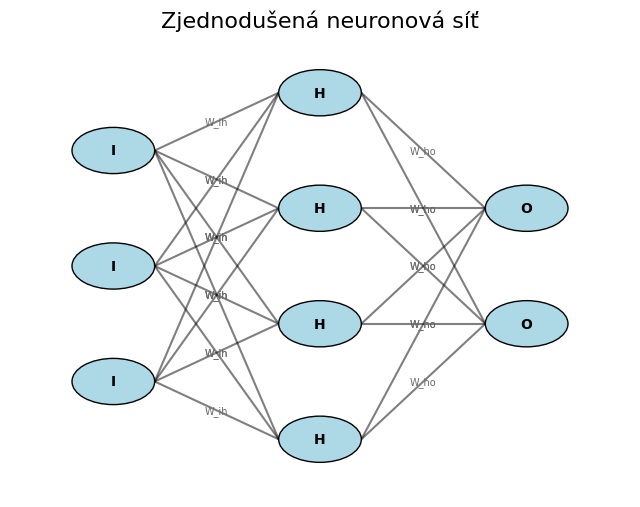

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Vytvoření obrázku a os
fig, ax = plt.subplots(figsize=(8, 6))

# Definice vrstev a počtu neuronů
input_layer_nodes = 3
hidden_layer_nodes = 4
output_layer_nodes = 2

# Souřadnice neuronů pro každou vrstvu
layer_coords = {
    'input': [(0, i) for i in np.linspace(-1, 1, input_layer_nodes)],
    'hidden': [(1, i) for i in np.linspace(-1.5, 1.5, hidden_layer_nodes)],
    'output': [(2, i) for i in np.linspace(-0.5, 0.5, output_layer_nodes)]
}

# Vykreslení neuronů
neuron_radius = 0.2
for layer_name, nodes in layer_coords.items():
    for x, y in nodes:
        circle = plt.Circle((x, y), neuron_radius, color='lightblue', ec='black', zorder=4)
        ax.add_artist(circle)
        ax.text(x, y, layer_name[0].upper(), ha='center', va='center', fontsize=10, weight='bold', zorder=5) # Označení prvním písmenem

# Vykreslení propojení
def draw_connections(from_layer, to_layer, weight_label):
    for x1, y1 in layer_coords[from_layer]:
        for x2, y2 in layer_coords[to_layer]:
            # Vykreslení spojovací čáry
            ax.plot([x1 + neuron_radius, x2 - neuron_radius], [y1, y2], 'k-', alpha=0.5, zorder=1)
            # Přidání popisku pro váhu
            mid_x = (x1 + x2) / 2
            mid_y = (y1 + y2) / 2
            ax.text(mid_x, mid_y, weight_label, ha='center', va='center', fontsize=7, color='dimgray', zorder=3)

draw_connections('input', 'hidden', 'W_ih')
draw_connections('hidden', 'output', 'W_ho')

# Nastavení limitů grafu a odstranění os
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-2, 2)
ax.axis('off')
ax.set_title("Zjednodušená neuronová síť", fontsize=16)

plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML # Pro zobrazení animace v Colabu

# 1. Vstupní data
input_data = np.array([1.0, 2.0, 3.0]) # Příklad vstupních příznaků

# 2. Definice vah a biasů
weights_ih = np.array([
    [0.01, 0.1, 1, 0.1],
    [0.05, 0.5, 5, 0.5],
    [0.1, 1, 10, 0.1]
])
bias_h = np.array([0.1, 0.2, 0.3, 0.4]) # Bias pro skrytou vrstvu
weights_ho = np.array([
    [0.01, 0.1],
    [0.02, 0.2],
    [0.03, 0.3],
    [0.04, 0.4]
])
bias_o = np.array([0.1, 0.2]) # Bias pro výstupní vrstvu

# 3. Výpočet forward pass (tyto hodnoty se zobrazí v animaci)
hidden_layer_values = np.dot(input_data, weights_ih) + bias_h
output_layer_values = np.dot(hidden_layer_values, weights_ho) + bias_o

# --- Nastavení animace ---
fig, ax = plt.subplots(figsize=(10, 7))
ax.set_aspect('equal')
ax.axis('off')
ax.set_title("Forward Pass Neuronové Sítě", fontsize=16)

# Definování vrstev a počtu neuronů
input_layer_nodes = len(input_data)
hidden_layer_nodes = weights_ih.shape[1] # Z rozměrů weights_ih
output_layer_nodes = weights_ho.shape[1] # Z rozměrů weights_ho

# Souřadnice neuronů pro každou vrstvu (upravené pro lepší rozestupy)
layer_coords = {
    'input': [(0, i) for i in np.linspace(-1, 1, input_layer_nodes)],
    'hidden': [(1.5, i) for i in np.linspace(-1.8, 1.8, hidden_layer_nodes)], # Širší rozptyl
    'output': [(3, i) for i in np.linspace(-0.8, 0.8, output_layer_nodes)] # Upravená pozice
}

neuron_radius = 0.25 # Mírně větší pro lepší viditelnost

# Uložení objektů neuronů a textů pro animaci
all_neurons = []
all_neuron_texts = []
all_connection_lines = []
all_connection_labels = [] # Pro uložení textových objektů popisků vah

# Vykreslení neuronů
# Vstupní vrstva
for x_pos, y_pos in layer_coords['input']:
    circle = plt.Circle((x_pos, y_pos), neuron_radius, color='lightblue', ec='black', zorder=4)
    ax.add_artist(circle)
    all_neurons.append(circle)
    text = ax.text(x_pos, y_pos, '', ha='center', va='center', fontsize=10, weight='bold', color='black', zorder=5)
    all_neuron_texts.append(text)

# Skrytá vrstva
for x_pos, y_pos in layer_coords['hidden']:
    circle = plt.Circle((x_pos, y_pos), neuron_radius, color='lightblue', ec='black', zorder=4)
    ax.add_artist(circle)
    all_neurons.append(circle)
    text = ax.text(x_pos, y_pos, '', ha='center', va='center', fontsize=10, weight='bold', color='black', zorder=5)
    all_neuron_texts.append(text)

# Výstupní vrstva
for x_pos, y_pos in layer_coords['output']:
    circle = plt.Circle((x_pos, y_pos), neuron_radius, color='lightblue', ec='black', zorder=4)
    ax.add_artist(circle)
    all_neurons.append(circle)
    text = ax.text(x_pos, y_pos, '', ha='center', va='center', fontsize=10, weight='bold', color='black', zorder=5)
    all_neuron_texts.append(text)


# Vytvoření propojení a jejich popisků
def create_connections_and_labels(from_layer_name, to_layer_name, weights_matrix):
    for i, (x1, y1) in enumerate(layer_coords[from_layer_name]):
        for j, (x2, y2) in enumerate(layer_coords[to_layer_name]):
            line, = ax.plot([x1 + neuron_radius, x2 - neuron_radius], [y1, y2], 'k-', alpha=0.3, zorder=1)
            all_connection_lines.append(line)

            # Přidání popisku váhy k propojení
            mid_x = (x1 + x2) / 2
            mid_y = (y1 + y2) / 2
            weight_val = weights_matrix[i, j]
            # Zvětšená velikost písma pro lepší viditelnost
            label = ax.text(mid_x, mid_y + 0.1, f'{weight_val:.2f}', ha='center', va='center', fontsize=10, color='dimgray', zorder=3, alpha=0) # Výchozí nastavení je skryté
            all_connection_labels.append(label)

create_connections_and_labels('input', 'hidden', weights_ih)
create_connections_and_labels('hidden', 'output', weights_ho)

# Nastavení limitů grafu
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(-2.5, 2.5)

# Výpočet offsetů indexů neuronů
input_start_idx = 0
hidden_start_idx = input_layer_nodes
output_start_idx = input_layer_nodes + hidden_layer_nodes

# Výpočet offsetů indexů propojení
ih_conn_start_idx = 0
ho_conn_start_idx = input_layer_nodes * hidden_layer_nodes

# Výpočet celkového počtu snímků pro animaci
TOTAL_FRAMES = input_layer_nodes + hidden_layer_nodes * 2 + output_layer_nodes * 2

def update(frame):
    # Obnovení všech spojení a popisků na výchozí hodnoty (skryté) na začátku každého snímku
    for line in all_connection_lines:
        line.set_alpha(0.3)
        line.set_color('k')
    for label in all_connection_labels:
        label.set_alpha(0)

    # Obnovení všech barev neuronů a textů na výchozí hodnoty (světle modrá, prázdný text)
    for i in range(len(all_neurons)):
        all_neurons[i].set_facecolor('lightblue')
        all_neuron_texts[i].set_text('')

    # --- Logika průběhu snímků ---
    current_frame_counter = 0

    # Fáze 1: Postupné zobrazení vstupních neuronů
    for i_node in range(input_layer_nodes):
        # Vykreslení aktuálního vstupního neuronu
        if frame >= current_frame_counter:
            all_neuron_texts[input_start_idx + i_node].set_text(f'{input_data[i_node]:.2f}')
            all_neurons[input_start_idx + i_node].set_facecolor('skyblue')
        current_frame_counter += 1 # Posun počítadla snímků pro další vstupní neuron

    # Fáze 2: Výpočty skryté vrstvy (váhy k neuronu, poté hodnota neuronu)
    for h_idx in range(hidden_layer_nodes):
        # Podfáze A: Zobrazení příchozích vah pro aktuální skrytý neuron
        if frame == current_frame_counter:
            # Zvýraznění vah vedoucích do tohoto skrytého neuronu
            for i_node in range(input_layer_nodes):
                conn_idx = ih_conn_start_idx + i_node * hidden_layer_nodes + h_idx
                all_connection_lines[conn_idx].set_alpha(0.8)
                all_connection_lines[conn_idx].set_color('blue')
                all_connection_labels[conn_idx].set_alpha(1)
        current_frame_counter += 1 # Posun počítadla snímků pro hodnotu neuronu

        # Podfáze B: Zobrazení vypočítané hodnoty pro aktuální skrytý neuron
        if frame >= current_frame_counter: # Použito >= protože tato hodnota neuronu musí přetrvat
            all_neuron_texts[hidden_start_idx + h_idx].set_text(f'{hidden_layer_values[h_idx]:.2f}')
            all_neurons[hidden_start_idx + h_idx].set_facecolor('lightgreen')
        current_frame_counter += 1 # Posun počítadla snímků pro váhy dalšího skrytého neuronu


    # Fáze 3: Výpočty výstupní vrstvy (váhy k neuronu, poté hodnota neuronu)
    for o_idx in range(output_layer_nodes):
        # Podfáze A: Zobrazení příchozích vah pro aktuální výstupní neuron
        if frame == current_frame_counter:
            # Zvýraznění vah vedoucích do tohoto výstupního neuronu
            for h_node in range(hidden_layer_nodes):
                conn_idx = ho_conn_start_idx + h_node * output_layer_nodes + o_idx
                all_connection_lines[conn_idx].set_alpha(0.8)
                all_connection_lines[conn_idx].set_color('red')
                all_connection_labels[conn_idx].set_alpha(1)
        current_frame_counter += 1 # Posun počítadla snímků pro hodnotu neuronu

        # Podfáze B: Zobrazení vypočítané hodnoty pro aktuální výstupní neuron
        if frame >= current_frame_counter: # Použito >= protože tato hodnota neuronu musí přetrvat
            all_neuron_texts[output_start_idx + o_idx].set_text(f'{output_layer_values[o_idx]:.2f}')
            all_neurons[output_start_idx + o_idx].set_facecolor('salmon')
        current_frame_counter += 1 # Posun počítadla srážek pro váhy dalšího výstupního neuronu


    return tuple(all_neurons) + tuple(all_neuron_texts) + tuple(all_connection_lines) + tuple(all_connection_labels)

# Vytvoření animace s více snímky
ani = animation.FuncAnimation(fig, update, frames=TOTAL_FRAMES, interval=1500, blit=True, repeat=False)

# Zobrazení animace
plt.close(fig) # Zamezení zobrazení statického grafu
print("Přehrávání animace forward passu...")
display(HTML(ani.to_jshtml()))

# Původní výpisy jako shrnutí
print("\n--- Summary of Forward Pass ---")
print("Vstupní data:", input_data)
print("\nVáhy input-hidden (W_ih):\n", weights_ih)
print("Bias pro hidden vrstvu:", bias_h)
print("\nHidden layer hodnoty (vážený součet + bias):", hidden_layer_values)
print("\nVáhy hidden-output (W_ho):\n", weights_ho)
print("Bias pro output vrstvu:", bias_o)
print("\nOutput layer hodnoty (vážený součet + bias):", output_layer_values)

Přehrávání animace forward passu...



--- Summary of Forward Pass ---
Vstupní data: [1. 2. 3.]

Váhy input-hidden (W_ih):
 [[ 0.01  0.1   1.    0.1 ]
 [ 0.05  0.5   5.    0.5 ]
 [ 0.1   1.   10.    0.1 ]]
Bias pro hidden vrstvu: [0.1 0.2 0.3 0.4]

Hidden layer hodnoty (vážený součet + bias): [ 0.51  4.3  41.3   1.8 ]

Váhy hidden-output (W_ho):
 [[0.01 0.1 ]
 [0.02 0.2 ]
 [0.03 0.3 ]
 [0.04 0.4 ]]
Bias pro output vrstvu: [0.1 0.2]

Output layer hodnoty (vážený součet + bias): [ 1.5021 14.221 ]


## Jak se vypočítávají váhy

### Gradientní sestup (Gradient Descent)

**Co je to?**

Gradientní sestup je jeden z nejdůležitějších algoritmů používaných k "učení" neuronových sítí. Jeho hlavním účelem je najít optimální hodnoty pro **váhy (W)** a **bias (b)** sítě tak, aby síť dělala co nejlepší předpovědi.

**Jak to funguje (jednoduše):**

1.  **Funkce chyby (Loss Function):** Představte si, že máte funkci, která vám řekne, jak moc se síť mýlí ve svých předpovědích. Čím vyšší chyba, tím horší předpověď. Cílem je tuto chybu minimalizovat.

2.  **Sklon (Gradient):** Algoritmus spočítá "sklon" této funkce chyby (gradient). Sklon nám ukazuje směr, kterým se chyba zvyšuje nejrychleji. Když chceme chybu zmenšit, musíme jít *proti* tomuto sklonu.

3.  **Postupné úpravy (step):** Gradientní sestup pak váhy a bias **postupně upravuje** v malých krocích, a to právě ve směru, který chybu snižuje. Je to jako jít dolů z kopce – každý krok uděláte směrem, který vede nejrychleji dolů, dokud nedosáhnete "dna" (minimální chyby).

4.  **Learning Rate:** Velikost těchto kroků je určena takzvanou Learnig rate. Pokud je moc velká, můžete přeskočit minimum. Pokud je moc malá, bude učení trvat dlouho.

euronová síť se učí tak, že opakovaně počítá chybu, určuje "směr poklesu" chyby a pak nepatrně upravuje své vnitřní parametry (váhy a bias), aby se této chybě vyhnula, dokud nedosáhne bodu, kde už se chyba moc nezmenšuje.

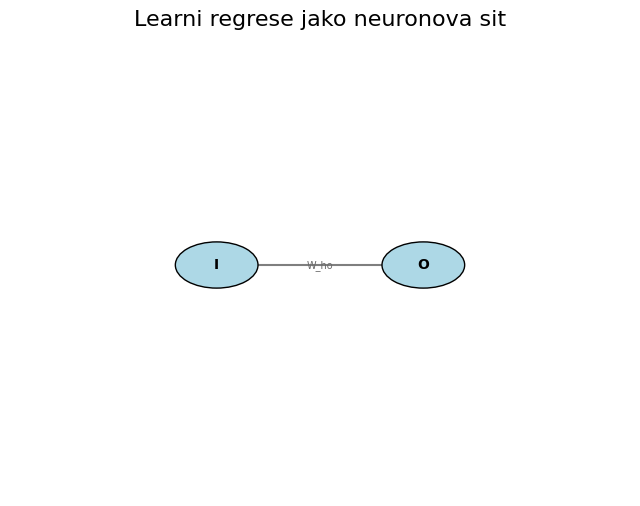

In [3]:
# Vytvoření obrázku a os
fig, ax = plt.subplots(figsize=(8, 6))

# Definice vrstev a počtu neuronů
input_layer_nodes = 1
output_layer_nodes = 1

# Souřadnice neuronů pro každou vrstvu
layer_coords = {
    'input': [(0.5, 0)],
    'output': [(1.5, 0)]
}

# Vykreslení neuronů
neuron_radius = 0.2
for layer_name, nodes in layer_coords.items():
    for x, y in nodes:
        circle = plt.Circle((x, y), neuron_radius, color='lightblue', ec='black', zorder=4)
        ax.add_artist(circle)
        ax.text(x, y, layer_name[0].upper(), ha='center', va='center', fontsize=10, weight='bold', zorder=5) # Označení prvním písmenem

# Vykreslení propojení
def draw_connections(from_layer, to_layer, weight_label):
    for x1, y1 in layer_coords[from_layer]:
        for x2, y2 in layer_coords[to_layer]:
            # Vykreslení spojovací čáry
            ax.plot([x1 + neuron_radius, x2 - neuron_radius], [y1, y2], 'k-', alpha=0.5, zorder=1)
            # Přidání popisku pro váhu
            mid_x = (x1 + x2) / 2
            mid_y = (y1 + y2) / 2
            ax.text(mid_x, mid_y, weight_label, ha='center', va='center', fontsize=7, color='dimgray', zorder=3)

draw_connections('input', 'output', 'W_ho')

# Nastavení limitů grafu a odstranění os
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(-2, 2)
ax.axis('off')
ax.set_title("Learni regrese jako neuronova sit", fontsize=16)

plt.show()

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import IntSlider, FloatSlider, Button, VBox, Output

# ------------------------------------------------------------------
# 1. Generování syntetických dat (přesunuto mimo funkci, protože jsou pro tuto interakci statická)
# ------------------------------------------------------------------
np.random.seed(42)
x = np.random.randn(10000, 1) # 100 náhodných hodnot mezi 0 a 1
x.sort(axis=0) # Seřazení x pro jasné zobrazení po částech lineární funkce v grafu

true_weight = 3 # Toto bude nyní pouze ilustrativní cíl pro lineární proložení, nepoužívá se přímo pro generování y
bias = 0.5      # Toto bude nyní pouze ilustrativní cíl pro lineární proložení, nepoužívá se přímo pro generování y

# Definování bodů zlomu pro po částech lineární funkci
break_point_1 = -1.0
break_point_2 = 1.0

# Generování y s po částech lineárními úseky
y_base = np.zeros_like(x)

# Úsek 1: x <= break_point_1 (rostoucí)
mask1 = x <= break_point_1
y_base[mask1] = 2 * x[mask1] + 0.1

# Úsek 2: break_point_1 < x <= break_point_2 (stabilní)
mask2 = (x > break_point_1) & (x <= break_point_2)
stable_y_value = 2 * break_point_1 + 0.1 # Hodnota na konci prvního úseku
y_base[mask2] = stable_y_value

# Úsek 3: x > break_point_2 (opět rostoucí)
mask3 = x > break_point_2
start_y_segment3 = stable_y_value
slope_segment3 = 3
y_base[mask3] = slope_segment3 * (x[mask3] - break_point_2) + start_y_segment3

# Přidání šumu
y = y_base + np.random.randn(10000, 1) * 0.2 # Snížený šum pro jasnější vzor

# ------------------------------------------------------------------
# Funkce pro spuštění gradientního sestupu a vygenerování animace
# ------------------------------------------------------------------
def run_gradient_descent_animation(n_iterations_val, learning_rate_val):
    # 2. Inicializace parametrů
    np.random.seed(1) # Reprodukovatelná počáteční váha a bias pro animaci
    w = np.random.randn(1, 1)
    b = np.random.randn(1, 1)

    print(f"Původní váha: {w[0][0]:.4f}")
    print(f"Původní bias: {b[0][0]:.4f}")

    learning_rate = learning_rate_val # Použití learning rate ze slideru

    w_history = []
    b_history = []
    loss_history = []
    dw_history = []

    # 3. Gradientní sestup
    for iteration in range(n_iterations_val): # Použití počtu iterací ze slideru
        y_pred = np.dot(x, w) + b
        loss = np.mean((y_pred - y) ** 2)

        d_w = (2 / len(x)) * np.dot(x.T, (y_pred - y))
        d_b = (2 / len(x)) * np.sum(y_pred - y)

        w_history.append(w[0][0])
        b_history.append(b[0][0])
        loss_history.append(loss)
        dw_history.append(d_w[0][0])

        w = w - learning_rate * d_w
        b = b - learning_rate * d_b

    # ------------------------------------------------------------------
    # 4. Animace
    # ------------------------------------------------------------------

    fig, (ax_fit, ax_loss, ax_dw) = plt.subplots(1, 3, figsize=(16, 4.5))

    # --- levý graf: data + fitovaná přímka ---
    ax_fit.scatter(x, y, s=15, alpha=0.6, color="#378ADD", label="data")
    line_fit, = ax_fit.plot([], [], color="#D85A30", linewidth=2, label="y = wx + b")
    x_line = np.array([x.min(), x.max()])
    ax_fit.set_xlim(x.min() - 0.5, x.max() + 0.5)
    ax_fit.set_ylim(y.min() - 2, y.max() + 2)
    ax_fit.set_xlabel("x")
    ax_fit.set_ylabel("y")
    ax_fit.set_title("Fit přímky během tréninku")
    ax_fit.legend(loc="upper left")
    text_params = ax_fit.text(0.02, 0.02, "", transform=ax_fit.transAxes, fontsize=10)

    # --- střední graf: vývoj MSE ztráty ---
    ax_loss.set_xlim(0, n_iterations_val) # Použití počtu iterací
    ax_loss.set_ylim(min(loss_history) * 0.95, max(loss_history) * 1.05)
    ax_loss.set_xlabel("iterace")
    ax_loss.set_ylabel("MSE")
    ax_loss.set_title("Průběh loss funkce")
    line_loss, = ax_loss.plot([], [], color="#D85A30", linewidth=2)

    # --- pravý graf: vývoj gradientu w ---
    ax_dw.set_xlim(0, n_iterations_val) # Použití počtu iterací
    ax_dw.set_ylim(min(dw_history), max(dw_history))
    ax_dw.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax_dw.set_xlabel("iterace")
    ax_dw.set_ylabel("d_w (gradient w)")
    ax_dw.set_title("Průběh gradientu w")
    line_dw, = ax_dw.plot([], [], color="#5CB85C", linewidth=2)

    fig.tight_layout()

    def init():
        line_fit.set_data([], [])
        line_loss.set_data([], [])
        line_dw.set_data([], [])
        text_params.set_text("")
        return line_fit, line_loss, line_dw, text_params

    def update(i):
        w_i = w_history[i]
        b_i = b_history[i]
        y_line = w_i * x_line + b_i
        line_fit.set_data(x_line, y_line)
        text_params.set_text(f"iterace {i}\nw = {w_i:.3f}\nb = {b_i:.3f}\nMSE = {loss_history[i]:.3f}\nd_w = {dw_history[i]:.3f}")

        line_loss.set_data(range(i + 1), loss_history[: i + 1])
        line_dw.set_data(range(i + 1), dw_history[: i + 1])

        return line_fit, line_loss, line_dw, text_params

    anim = FuncAnimation(
        fig,
        update,
        frames=n_iterations_val,
        init_func=init,
        interval=200,
        blit=True,
        repeat=False,
    )

    plt.close(fig) # Zamezení zobrazení statického grafu

    # Zobrazení HTML s animací
    display(HTML(anim.to_jshtml()))

# ------------------------------------------------------------------
# Vytvoření interaktivních widgetů
# ------------------------------------------------------------------
# Definování slideru pro počet iterací
n_iterations_slider = IntSlider(
    min=10,
    max=50,
    step=5,
    value=10, # Výchozí hodnota odpovídá původnímu kódu
    description='Počet iterací:',
    continuous_update=False # Aktualizovat pouze při uvolnění tlačítka myši
)

# Definování slideru pro learning rate
learning_rate_slider = FloatSlider(
    min=0.001,
    max=0.1,
    step=0.001,
    value=0.01, # Výchozí hodnota odpovídá původnímu kódu
    description='Learning Rate:',
    continuous_update=False
)

# Vytvoření tlačítka "Spustit výpočty"
apply_button = Button(description="Spustit výpočty")

# Vytvoření výstupního widgetu pro zachycení animace a výpisů
output_area = Output()

# Definování callback funkce pro kliknutí na tlačítko
def on_button_click(b):
    with output_area:
        output_area.clear_output(wait=True) # Vymazání předchozího výstupu
        run_gradient_descent_animation(
            n_iterations_slider.value,
            learning_rate_slider.value
        )

# Propojení callback funkce s tlačítkem
apply_button.on_click(on_button_click)

# Zobrazení widgetů
display(VBox([n_iterations_slider, learning_rate_slider, apply_button, output_area]))

# Výchozí spuštění pro zobrazení při prvním načtení zápisníku
with output_area:
    run_gradient_descent_animation(
        n_iterations_slider.value,
        learning_rate_slider.value
    )

## Implementace v pytorch

V této části si ukážeme, jak teorii gradientního sestupu převést do praxe pomocí knihovny **PyTorch**.

Sestavíme jednoduchý lineární model (`nn.Linear(1, 1)`), definujeme chybovou funkci MSE (`nn.MSELoss`) a optimalizátor SGD (`torch.optim.SGD`). Následně projdeme trénovacím cyklem (training loop), kde budeme v každém kroku počítat gradienty a aktualizovat váhy modelu tak, aby co nejlépe aproximoval naše trénovací data.

In [5]:
import torch.nn  as nn
import torch

lr=0.01
n_iterations = 5000

x_tensor = torch.tensor(x, dtype=torch.float)
y_tensor = torch.tensor(y, dtype=torch.float)
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# training loop
for epoch in range(n_iterations):
    optimizer.zero_grad()
    y_pred = model(x_tensor)
    loss = loss_fn(y_pred, y_tensor)
    loss.backward()  # gradient
    optimizer.step()  # w - lr * gradient
    with torch.no_grad():
      params = list(model.parameters())
      if epoch % 1000 == 0:
          print(f"Iterace {epoch} - loss: {loss.item():.3}")
          print(f"Estimated: b={params[1].item():.2f} w={params[0].item():.2f}")
print(f"Final loss: {loss.item():.3}")
print(f"Final estimated: b={params[1].item():.2f} w={params[0].item():.2f}")


Iterace 0 - loss: 7.23
Estimated: b=0.39 w=-0.49
Iterace 1000 - loss: 0.387
Estimated: b=-1.81 w=0.80
Iterace 2000 - loss: 0.387
Estimated: b=-1.81 w=0.80
Iterace 3000 - loss: 0.387
Estimated: b=-1.81 w=0.80
Iterace 4000 - loss: 0.387
Estimated: b=-1.81 w=0.80
Final loss: 0.387
Final estimated: b=-1.81 w=0.80


### Proč používáme více vrstev?

Dosud jsme pracovali pouze s jednou vrstvou (jednoduchou lineární regresí). Ta dokáže najít pouze přímé vztahy (přímku). Reálné problémy jsou však složitější.

*   **Hluboké sítě (Deep Learning):** Přidáním více skrytých vrstev za sebe umožňujeme síti učit se reprezentace na různých úrovních abstrakce.
*   **Kombinace vrstev:** V následujícím kódu vytvoříme sekvenční model `nn.Sequential` se dvěma lineárními vrstvami za sebou.

*Poznámka:* Pokud bychom za sebou poskládali pouze lineární vrstvy bez nelineární aktivační funkce (jako je ReLU), síť by se stále chovala jako jedna jediná lineární vrstva. Proto hned v další části uvidíme, proč je klíčové přidat nelinearitu.

In [ ]:
lr=0.01
n_iterations = 5000

model = nn.Sequential(
    nn.Linear(1, 4),
    nn.Linear(4, 1)
  )
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# training loop
for epoch in range(n_iterations):
    optimizer.zero_grad()
    y_pred = model(x_tensor)
    loss = loss_fn(y_pred, y_tensor)
    loss.backward()  # gradient
    optimizer.step()  # w - lr * gradient
    with torch.no_grad():
      params = list(model.parameters())
      if epoch % 1000 == 0:
          print(f"Iterace {epoch} - loss: {loss.item():.3}")
print(f"Final loss: {loss.item():.3}")

Iterace 0 - loss: 4.43
Iterace 1000 - loss: 0.387


### Proč potřebujeme nelinearitu?

Pokud bychom v neuronové síti používali pouze lineární operace (jako je násobení váhami a sčítání: $z = x \cdot w + b$), celá naše síť by se chovala jako **jedna jediná velká lineární rovnice** (např. jednoduchá přímka). Bez ohledu na to, kolik vrstev bychom za sebou měli, nedokázali bychom modelovat složitější vztahy než obyčejné přímky.

Reálná data (např. obrázky, lidská řeč nebo netriviální vzorce) jsou ale téměř vždy **nelineární** (mají křivky, zlomy, složité tvary).

Abychom síti umožnili tyto složité tvary pochopit, musíme po každém lineárním kroku provést tzv. **aktivační funkci**, která do sítě vnese **nelinearitu**.

---

### Co je to ReLU?

Jednou z nejpopulárnějších a nejjednodušších aktivačních funkcí je **ReLU** (*Rectified Linear Unit*).

Matematický zápis pro jeden neuron vypadá takto:
$$z = \text{ReLU}(x \cdot w + b)$$

Kde:
*   $x \cdot w + b$ je klasický lineární výpočet (vstup $\times$ váha $+$ bias).
*   $\text{ReLU}$ vezme tento výsledek a aplikuje na něj velmi jednoduché pravidlo:

$$\text{ReLU}(a) = \max(0, a)$$

*   **Pokud je výsledek kladný**, nechá ho být (např. z $3.5$ udělá $3.5$).
*   **Pokud je výsledek záporný**, prostě ho zahodí a nahradí nulou (např. z $-2.1$ udělá $0$).

### Proč to funguje?

Tento jednoduchý "zlom" v nule (který si můžete představit jako koleno) umožňuje síti skládat tyto zlomy k sobě. Kombinací mnoha takových neuronů dokáže síť aproximovat (napodobit) téměř jakoukoliv složitou křivku nebo funkci.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def relu(x):
    return np.maximum(0, x)

x_values = np.linspace(-5, 5, 100)
y_values = relu(x_values)

plt.figure(figsize=(8, 5))
plt.plot(x_values, y_values, label='ReLU(x) = max(0, x)', color='blue', linewidth=2)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title('ReLU (Rectified Linear Unit) Activation Function')
plt.xlabel('Input (x)')
plt.ylabel('Output (ReLU(x))')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()

In [ ]:
x_relu = np.random.randn(100, 1)
x_relu.sort(axis=0)

y_relu1 = relu(-0.5 * x_relu + 0.1)
y_relu2 = relu(1.2 * x_relu - 0.5)
y_relu3 = relu(-2 * x_relu + 2.5)

fix, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 5))

ax1.plot(x_relu, y_relu1)
ax1.set_ylabel("ReLU(x)")
ax1.set_xlabel("x")
ax1.set_title("z1 = ReLU(-0.5 * x + 0.1)")

ax2.plot(x_relu, y_relu2)
ax2.set_xlabel("x")
ax2.set_title("z2 = ReLU(1.2 * x - 0.5)")

ax3.plot(x_relu, y_relu3)
ax3.set_xlabel("x")
ax3.set_title("z3 = ReLU(-2.0 * x + 3.0)")

ax4.plot(x_relu, y_relu1 + y_relu2 + y_relu3)
ax4.set_xlabel("x")
ax4.set_title("z1 + z2 + z3")

plt.show()

In [ ]:
lr=0.01
n_iterations = 100

model = nn.Sequential(
    nn.Linear(1, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
  )
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

# training loop
for epoch in range(n_iterations):
    optimizer.zero_grad()
    y_pred = model(x_tensor)
    loss = loss_fn(y_pred, y_tensor)
    loss.backward()  # gradient
    optimizer.step()  # w - lr * gradient
    with torch.no_grad():
      params = list(model.parameters())
      if epoch % 1000 == 0:
          print(f"Iterace {epoch} - loss: {loss.item():.3f}")
print(f"Final loss: {loss.item():.3f}")

In [ ]:
x_sim = torch.linspace(-5, 5, 100, dtype=torch.float).reshape(-1, 1)

model.eval()
with torch.no_grad():
    y_pred = model(x_sim).numpy()

plt.scatter(x_tensor, y_tensor)
plt.plot(x_sim, y_pred, color="red")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = (torch.tensor(t, dtype=torch.float) for t in train_test_split(x, y, test_size = 0.1))


lr=0.01
n_iterations = 100

model = nn.Sequential(
    nn.Linear(1, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
  )
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

loss_train = []
loss_test = []
# training loop
for epoch in range(n_iterations):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = loss_fn(y_pred, y_train)
    loss.backward()  # gradient
    optimizer.step()  # w - lr * gradient
    model.eval()
    with torch.no_grad():
      loss_t = loss_fn(model(x_test), y_test)
      if epoch % 200 == 0:
          print(f"Iterace {epoch} - loss: {loss_t.item():.3f}")
      loss_train.append(loss.item())
      loss_test.append(loss_t.item())
print(f"Final loss: {loss_t.item():.3f}")

plt.plot(loss_train, label="train")
plt.plot(loss_test, label="test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Trénovací a testovací loss")
plt.legend()
plt.show()

### Stručné shrnutí NLP příkladu

V následující části si ukážeme praktický příklad klasifikace textu v češtině:

1.  **Načtení dat**: Použijeme dataset `czech_news_dataset_v2` a stáhneme si novinové titulky z různých rubrik (např. Zahraniční, Domácí, Sport, Kultura).
2.  **Příprava textu (Tokenizace)**: Převedeme české titulky na čísla pomocí metody **TF-IDF Vectorizer**, která vytvoří matici četností nejdůležitějších slov (v našem případě až 10000 slov).
3.  **Příprava PyTorch datasetu**: Vytvoříme tenzory a data naložíme do `DataLoaderu` pro trénování v dávkách (batche).
4.  **Trénování neuronové sítě**: Sestavíme model s vrstvami `Linear`, `ReLU` a `Dropout` a vytrénujeme jej k předpovídání správné kategorie zpráv.
5.  **Evaluace a predikce**: Na závěr otestujeme úspěšnost modelu na testovacích datech a vyzkoušíme si předpověď kategorie pro vlastní libovolný titulek.

In [ ]:
from datasets import load_dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Načtení streamovaného datasetu
raw_dataset = load_dataset("hynky/czech_news_dataset_v2", streaming=True)
# https://huggingface.co/datasets/hynky/czech_news_dataset_v2
# Stažení a uložení prvních vzorků
n = 80_000
print(f"Načítám {n} vzorků...")
tmp = list(raw_dataset["train"].take(n))
tmp = [dat for dat in tmp if dat["category"] != 0]  # 0 je nezatrideny
df = pd.DataFrame(tmp)

# Vybereme pouze kategorie, které mají alespoň 1000 příkladů
category_counts = df["category"].value_counts()
valid_categories = category_counts[category_counts >= 1000].index
df = df[df["category"].isin(valid_categories)].copy()

# Aktualizujeme seznam tmp podle vyfiltrovaného DataFrame
tmp = df.to_dict(orient="records")

# Zajistit, ze categories jsou od 0 do max(categories)
encoder = LabelEncoder()
seq_categories = encoder.fit_transform(df["category"])
for i in range(len(tmp)):
  tmp[i]["category"] = seq_categories[i]

# Zobrazení jednoho vzorku pro kontrolu
print("Ukázka dat:")
_ = [print(tmp[0][col], "\t") for col in ["headline", "category_unclean", "category"]]

labels = set()
_ = [labels.add((dat["category"], dat["category_unclean"])) for dat in tmp]
labels = pd.DataFrame(labels, columns=["category", "Label"])
# Seskupení podle kódu a spojení textových popisků pomocí '/ '
labels = labels.dropna().groupby("category")["Label"].apply(lambda x: " / ".join(sorted(set(x)))).reset_index()
labels.sort_values(by="category")
print(labels)

train, test = train_test_split(pd.DataFrame(tmp), test_size=0.05, stratify=pd.DataFrame(tmp)["category"])

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

x_train = train["headline"].to_list()
x_test = test["headline"].to_list()
y_train = train["category"].to_list()
y_test = test["category"].to_list()

tokenizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), max_df=0.9)
tokenizer.fit(x_train)

print(tokenizer.transform(x_train).shape)

X_train_dense = tokenizer.transform(x_train).toarray()
X_test_dense = tokenizer.transform(x_test).toarray()

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convert to PyTorch tensors. y_train/y_test are categorical labels (0-4), which must be torch.long
train_dataset = TensorDataset(
    torch.tensor(X_train_dense, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
test_dataset = TensorDataset(
    torch.tensor(X_test_dense, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

print("Trénovací dataset - počet vzorků:", len(train_dataset))
print("Testovací dataset - počet vzorků:", len(test_dataset))

# Získání a vytištění první dávky ukázkových dat z trénovacího loaderu
first_batch_x, first_batch_y = next(iter(train_loader))
print("\n--- První batch dat z train_loaderu ---")
print("Tvar feature (X_batch):", first_batch_x.shape)
print("Tvar target (y_batch):", first_batch_y.shape)

### Architektura modelu a trénování

V následující části nadefinujeme a vytrénujeme hlubokou neuronovou síť v PyTorch:

1.  **Model**: Vytvoříme plně propojenou síť (`nn.Sequential`) s vrstvami `Linear` pro transformaci dimenzí, `ReLU` jako nelineární aktivací a vrstvami `Dropout` pro regularizaci (prevence přetrénování).
2.  **Kritérium a Optimalizátor**: Použijeme klasifikační ztrátovou funkci `CrossEntropyLoss` a optimalizační algoritmus `Adam` s učením nastaveným na $0.001$.
3.  **Trénovací cyklus**: Projdeme $20$ epochami, kde v každé epoše zpracujeme trénovací data po dávkách (batche), spočítáme loss, provedeme zpětný průchod gradientu (`loss.backward()`) a aktualizujeme váhy. Průběžně sledujeme úspěšnost (accuracy) na testovacím setu.

In [ ]:
from sklearn.metrics import accuracy_score

lr=0.001
n_epochs = 25

model = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(train_dataset.tensors[0].shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, max(y_train) + 1),
  )
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

loss_train = []
loss_test = []
# training loop
for epoch in range(n_epochs):
    model.train()
    epoch_loss = 0
    epoch_eval_loss = 0
    accuracy = 0
    for X_batch, y_batch in train_loader:
      optimizer.zero_grad()
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)
      epoch_loss += loss.item()
      loss.backward()  # gradient
      optimizer.step()  # w - lr * gradient
    model.eval()
    with torch.no_grad():
      for X_batch, y_batch in test_loader:
        y_pred_eval = model(X_batch)
        loss_t = loss_fn(y_pred_eval, y_batch)
        epoch_eval_loss += loss_t.item()
        accuracy += accuracy_score(torch.argmax(y_pred_eval, axis=1), y_batch)

    mean_loss = epoch_loss / len(train_loader)
    mean_test_loss = epoch_eval_loss / len(test_loader)
    loss_train.append(mean_loss)
    loss_test.append(mean_test_loss)
    if (epoch + 1) % 5 == 0:
      print(f"Epoch: {epoch + 1}, train loss: {mean_loss:.3f}")
      print(f"Epoch: {epoch + 1}, test loss: {mean_test_loss:.3f}")
      print(f"Epoch: {epoch + 1}, test accuracy: {accuracy / len(test_loader):.2f}")

In [ ]:
plt.plot(loss_train, label="train")
plt.plot(loss_test, label="test")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Trénovací a testovací loss")
plt.show()

### Vyhodnocení modelu a ukázka predikcí

Nyní otestujeme náš vytrénovaný model na testovacích datech. Z testovacího subsetu vezmeme první batch (dávku) novinových titulků, necháme model předpovědět jejich kategorie a u každého ukážeme:
*   **Titulek zpráv** (Headline)
*   **Předpovězenou kategorii** (Predicted kategorie)
*   **Skutečnou kategorii** (Skutecna kategorie)
*   **Top 3 nejvíce pravděpodobné kategorie** a jejich procentuální jistotu vyjádřenou v softmax pravděpodobnostech

In [ ]:
x, y = next(iter(test_loader))
model.eval()
with torch.no_grad():
  y_pred_logit = model(x)
  y_pred_prob, y_pred_categories = nn.functional.softmax(y_pred_logit, dim=1).sort(axis=1, descending=True)


for i in range(10):
  print("Headline:", x_test[i])
  print("Predicted kategorie:", labels.loc[labels["category"] == y_pred_categories[i, 0].item(), "Label"].values[0])
  print("Skutecna kategorie",labels.loc[labels["category"] == y[i].item(), "Label"].values[0])
  print(f"top 3 % : {list(zip(y_pred_categories[i, :3], y_pred_prob[i, :3]))}")
  print("=" * 100, "\n")


In [ ]:
def predict_category(text, tokenizer, model, top_n):
  tokens = tokenizer.transform(text)
  logits = model(torch.tensor(tokens.toarray(), dtype=torch.float32))
  with torch.no_grad():
    y_pred_prob, y_pred_categories = nn.functional.softmax(logits, dim=1).sort(descending=True)


  return list(zip(labels.loc[labels["category"].isin(y_pred_categories[0, :top_n].numpy()), "Label"].values, y_pred_prob[0, :top_n].numpy()))

predict_category(["Volební účast v ČR byla průměrná"], tokenizer, model, 3)


Jak pouzit predtrenovane modely

In [ ]:
import torch
from transformers import AutoModel, AutoTokenizer

model_name = "Seznam/simcse-small-e-czech"  # Hugging Face link
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

input_texts = [
    "Dnes je výborné počasí na procházku po parku.",
    "Večer si oblíbím dobrý film a uvařím si čaj."
]

# Tokenize the input texts
batch_dict = tokenizer(input_texts, max_length=512, padding=True, truncation=True, return_tensors='pt')

outputs = model(**batch_dict)
embeddings = outputs.last_hidden_state[:, 0]  # Extract CLS token embeddings

similarity = torch.nn.functional.cosine_similarity(embeddings[0], embeddings[1], dim=0)


In [ ]:
batch_dict = tokenizer(x_train, max_length=512, padding=True, truncation=True, return_tensors='pt')

outputs = model(**batch_dict)
embeddings = outputs.last_hidden_state[:, 0]  # Extract CLS token embeddings